In [1]:
# CELL 1: Import libraries and set reproducibility

import os
import random
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    classification_report, confusion_matrix, accuracy_score,
    precision_score, recall_score, f1_score, roc_auc_score
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [2]:
# CELL 2: Find the dataset automatically in Kaggle

BASE_INPUT = "/kaggle/input"
data_path = None

for root, dirs, files in os.walk(BASE_INPUT):
    folder_names = {d.lower(): d for d in dirs}
    if "training" in folder_names and "testing" in folder_names:
        data_path = root
        train_path = os.path.join(root, folder_names["training"])
        test_path = os.path.join(root, folder_names["testing"])
        break

if data_path is None:
    raise FileNotFoundError(
        "Dataset not found. In Kaggle, click Add Input and attach "
        "'Brain Tumor MRI Dataset' by masoudnickparvar."
    )

print("Dataset path:", data_path)
print("Training path:", train_path)
print("Testing path:", test_path)

Dataset path: /kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset
Training path: /kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Training
Testing path: /kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Testing


In [3]:
# CELL 3: Inspect classes and count images

IMAGE_EXTENSIONS = (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff")

class_names = sorted([
    d for d in os.listdir(train_path)
    if os.path.isdir(os.path.join(train_path, d))
])

if len(class_names) < 2:
    raise ValueError("Expected multiple class folders inside Training.")

rows = []
for split_name, split_dir in [("Training", train_path), ("Testing", test_path)]:
    for class_name in class_names:
        class_dir = os.path.join(split_dir, class_name)
        count = sum(
            1 for f in os.listdir(class_dir)
            if f.lower().endswith(IMAGE_EXTENSIONS)
        ) if os.path.isdir(class_dir) else 0
        rows.append({"Split": split_name, "Class": class_name, "Images": count})

counts_df = pd.DataFrame(rows)
display(counts_df)
print("Total images:", int(counts_df["Images"].sum()))
print("Classes:", class_names)

,Split,Class,Images
0,Training,glioma,1400
1,Training,meningioma,1400
2,Training,notumor,1400
3,Training,pituitary,1400
4,Testing,glioma,400
5,Testing,meningioma,400
6,Testing,notumor,400
7,Testing,pituitary,400


Total images: 7200
Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


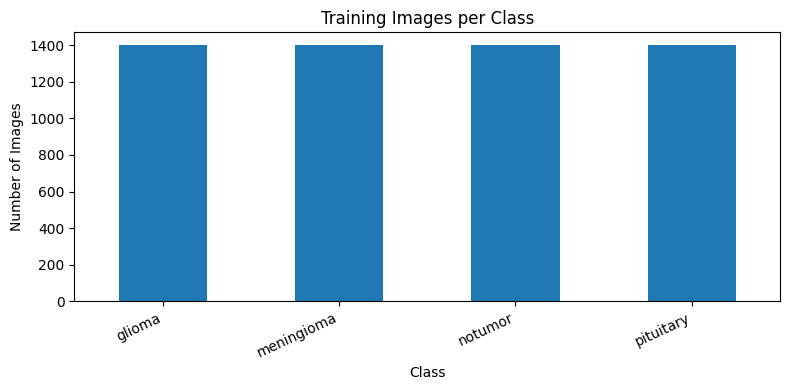

In [4]:
# CELL 4: Plot dataset distribution

train_counts = counts_df[counts_df["Split"] == "Training"].set_index("Class")["Images"]

plt.figure(figsize=(8, 4))
train_counts.reindex(class_names).plot(kind="bar")
plt.title("Training Images per Class")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

In [5]:
# CELL 5: Load image datasets

IMG_SIZE = (160, 160)
BATCH_SIZE = 32
EPOCHS_HEAD = 5
EPOCHS_FINE = 2

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_path,
    labels="inferred",
    label_mode="categorical",
    class_names=class_names,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    validation_split=0.15,
    subset="training",
    seed=SEED,
    shuffle=True
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    train_path,
    labels="inferred",
    label_mode="categorical",
    class_names=class_names,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    validation_split=0.15,
    subset="validation",
    seed=SEED,
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_path,
    labels="inferred",
    label_mode="categorical",
    class_names=class_names,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

NUM_CLASSES = len(class_names)
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

print("Training, validation and testing datasets loaded.")
print("Number of classes:", NUM_CLASSES)

Found 5600 files belonging to 4 classes.
Using 4760 files for training.
Found 5600 files belonging to 4 classes.
Using 840 files for validation.
Found 1600 files belonging to 4 classes.
Training, validation and testing datasets loaded.
Number of classes: 4


In [8]:
# CELL 6: Define a common transfer-learning model builder

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.10)
], name="data_augmentation")

def build_model(model_name):
    inputs = tf.keras.Input(shape=(*IMG_SIZE, 3))
    x = data_augmentation(inputs)

    if model_name == "VGG19":
        x = tf.keras.applications.vgg19.preprocess_input(x)
        base_model = tf.keras.applications.VGG19(
            include_top=False,
            weights="imagenet",
            input_shape=(*IMG_SIZE, 3)
        )
    elif model_name == "InceptionV3":
        x = tf.keras.applications.inception_v3.preprocess_input(x)
        base_model = tf.keras.applications.InceptionV3(
            include_top=False,
            weights="imagenet",
            input_shape=(*IMG_SIZE, 3)
        )
    else:
        raise ValueError("Unsupported model name")

    base_model.trainable = False
    x = base_model(x, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Dense(256, activation="relu")(x)
    x = tf.keras.layers.Dropout(0.4)(x)
    outputs = tf.keras.layers.Dense(NUM_CLASSES, activation="softmax")(x)

    model = tf.keras.Model(inputs, outputs, name=model_name)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model, base_model

In [9]:
# CELL 7: Build and train VGG19

model_vgg19, base_vgg19 = build_model("VGG19")
model_vgg19.summary()

callbacks_vgg = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=2, restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.2, patience=1, min_lr=1e-6
    )
]

history_vgg_head = model_vgg19.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_HEAD,
    callbacks=callbacks_vgg
)

80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "VGG19"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 160, 160,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ data_augmentation   │ (None, 160, 160,  │          0 │ input_layer[0][0] │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 160, 160)  │          0 │ data_augmentatio… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 160, 160)  │          0 │ data_augmentatio… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 160, 160)  │          0 │ data_augmentatio… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 160, 160,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 160, 160,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vgg19 (Functional)  │ (None, 5, 5, 512) │ 20,024,384 │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 512)       │          0 │ vgg19[0][0]       │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 512)       │      2,048 │ global_average_p… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 256)       │    131,328 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 256)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 4)         │      1,028 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 20,158,788 (76.90 MB)

 Trainable params: 133,380 (521.02 KB)

 Non-trainable params: 20,025,408 (76.39 MB)

Epoch 1/5
149/149 ━━━━━━━━━━━━━━━━━━━━ 45s 247ms/step - accuracy: 0.7588 - loss: 0.6431 - val_accuracy: 0.9619 - val_loss: 0.1197 - learning_rate: 0.0010
Epoch 2/5
149/149 ━━━━━━━━━━━━━━━━━━━━ 15s 98ms/step - accuracy: 0.8426 - loss: 0.4173 - val_accuracy: 0.9631 - val_loss: 0.1227 - learning_rate: 0.0010
Epoch 3/5
149/149 ━━━━━━━━━━━━━━━━━━━━ 15s 100ms/step - accuracy: 0.8710 - loss: 0.3403 - val_accuracy: 0.9905 - val_loss: 0.0528 - learning_rate: 2.0000e-04
Epoch 4/5
149/149 ━━━━━━━━━━━━━━━━━━━━ 15s 103ms/step - accuracy: 0.8874 - loss: 0.3017 - val_accuracy: 0.9905 - val_loss: 0.0515 - learning_rate: 2.0000e-04
Epoch 5/5
149/149 ━━━━━━━━━━━━━━━━━━━━ 16s 106ms/step - accuracy: 0.8891 - loss: 0.2873 - val_accuracy: 0.9929 - val_loss: 0.0413 - learning_rate: 2.0000e-04


In [10]:
# CELL 8: Fine-tune the last VGG19 layers

base_vgg19.trainable = True

# Freeze most layers and fine-tune only the last few convolution layers.
for layer in base_vgg19.layers[:-4]:
    layer.trainable = False

model_vgg19.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

history_vgg_fine = model_vgg19.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_FINE,
    callbacks=callbacks_vgg
)

Epoch 1/2
149/149 ━━━━━━━━━━━━━━━━━━━━ 23s 132ms/step - accuracy: 0.9048 - loss: 0.2646 - val_accuracy: 0.9964 - val_loss: 0.0245 - learning_rate: 1.0000e-05
Epoch 2/2
149/149 ━━━━━━━━━━━━━━━━━━━━ 20s 133ms/step - accuracy: 0.9267 - loss: 0.2047 - val_accuracy: 0.9964 - val_loss: 0.0155 - learning_rate: 1.0000e-05


In [11]:
# CELL 9: Build and train InceptionV3

model_inception, base_inception = build_model("InceptionV3")
model_inception.summary()

callbacks_inc = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=2, restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.2, patience=1, min_lr=1e-6
    )
]

history_inc_head = model_inception.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_HEAD,
    callbacks=callbacks_inc
)

87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "InceptionV3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ inception_v3 (Functional)       │ (None, 3, 3, 2048)     │    21,802,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_95          │ (None, 2048)           │         8,192 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,336,548 (85.21 MB)

 Trainable params: 529,668 (2.02 MB)

 Non-trainable params: 21,806,880 (83.19 MB)

Epoch 1/5
149/149 ━━━━━━━━━━━━━━━━━━━━ 21s 88ms/step - accuracy: 0.7691 - loss: 0.7869 - val_accuracy: 0.9524 - val_loss: 0.1576 - learning_rate: 0.0010
Epoch 2/5
149/149 ━━━━━━━━━━━━━━━━━━━━ 10s 64ms/step - accuracy: 0.8441 - loss: 0.4555 - val_accuracy: 0.9119 - val_loss: 0.2764 - learning_rate: 0.0010
Epoch 3/5
149/149 ━━━━━━━━━━━━━━━━━━━━ 10s 65ms/step - accuracy: 0.8821 - loss: 0.3211 - val_accuracy: 0.9440 - val_loss: 0.1681 - learning_rate: 2.0000e-04


In [12]:
# CELL 10: Fine-tune the last InceptionV3 layers

base_inception.trainable = True

# Unfreeze only the later layers; keep BatchNormalization layers frozen.
for layer in base_inception.layers[:-25]:
    layer.trainable = False
for layer in base_inception.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

model_inception.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

history_inc_fine = model_inception.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_FINE,
    callbacks=callbacks_inc
)

Epoch 1/2
149/149 ━━━━━━━━━━━━━━━━━━━━ 20s 85ms/step - accuracy: 0.8544 - loss: 0.4359 - val_accuracy: 0.9488 - val_loss: 0.1685 - learning_rate: 1.0000e-05
Epoch 2/2
149/149 ━━━━━━━━━━━━━━━━━━━━ 10s 67ms/step - accuracy: 0.8595 - loss: 0.3925 - val_accuracy: 0.9524 - val_loss: 0.1648 - learning_rate: 2.0000e-06


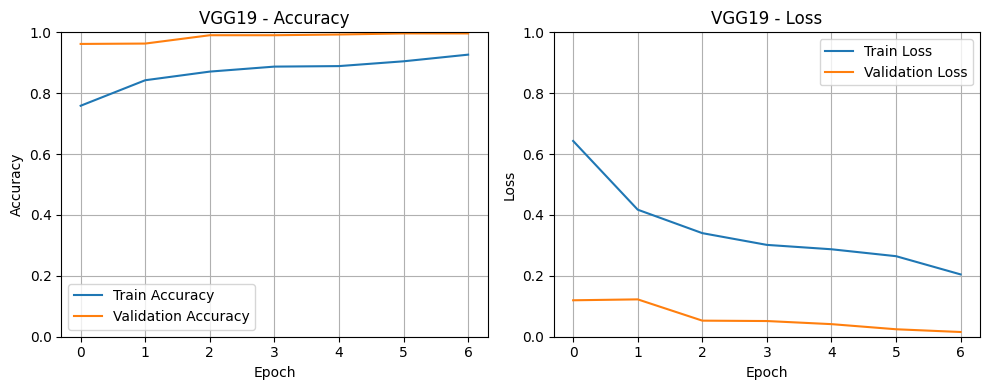

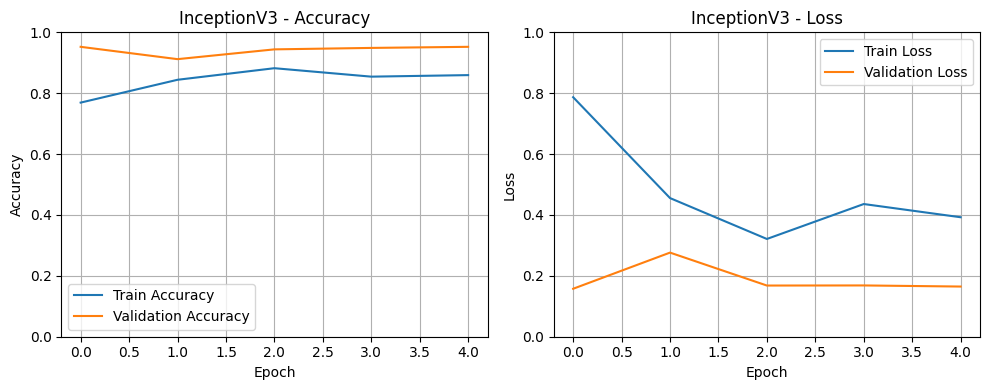

In [18]:

# CELL 11: Combine training history and plot accuracy/loss

def combine_histories(first, second):
    combined = {}
    for key in first.history:
        combined[key] = first.history[key] + second.history.get(key, [])
    return combined

histories = {
    "VGG19": combine_histories(history_vgg_head, history_vgg_fine),
    "InceptionV3": combine_histories(history_inc_head, history_inc_fine)
}

for model_name, history in histories.items():
    plt.figure(figsize=(10, 4))

    # Accuracy
    plt.subplot(1, 2, 1)
    plt.plot(history["accuracy"], label="Train Accuracy")
    plt.plot(history["val_accuracy"], label="Validation Accuracy")
    plt.title(model_name + " - Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.ylim(0, 1)
    plt.legend()
    plt.grid(True)

    # Loss
    plt.subplot(1, 2, 2)
    plt.plot(history["loss"], label="Train Loss")
    plt.plot(history["val_loss"], label="Validation Loss")
    plt.title(model_name + " - Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.ylim(0, 1)
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()


In [14]:
# CELL 12: Get true labels from the test dataset

y_true = np.concatenate([
    np.argmax(labels.numpy(), axis=1)
    for images, labels in test_ds
])

print("Test images:", len(y_true))
print("Class order:", class_names)

Test images: 1600
Class order: ['glioma', 'meningioma', 'notumor', 'pituitary']


50/50 ━━━━━━━━━━━━━━━━━━━━ 5s 90ms/step
\n =============== VGG19 ===============
              precision    recall  f1-score   support

      glioma       0.97      0.70      0.82       400
  meningioma       0.85      0.81      0.82       400
     notumor       0.87      1.00      0.93       400
   pituitary       0.85      0.99      0.91       400

    accuracy                           0.88      1600
   macro avg       0.88      0.88      0.87      1600
weighted avg       0.88      0.88      0.87      1600



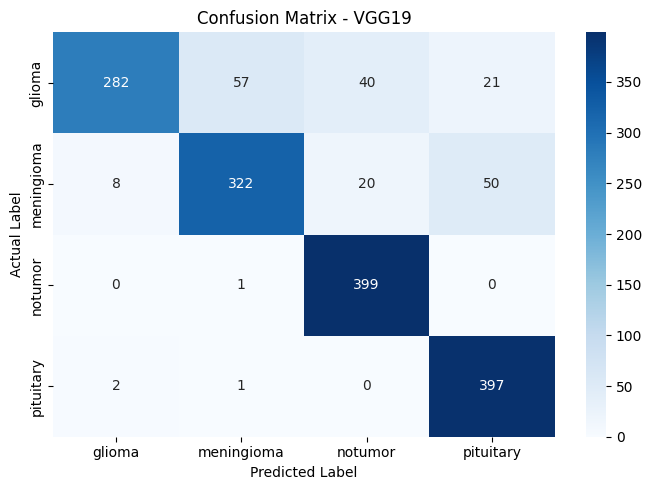

50/50 ━━━━━━━━━━━━━━━━━━━━ 5s 51ms/step
\n =============== InceptionV3 ===============
              precision    recall  f1-score   support

      glioma       0.88      0.68      0.76       400
  meningioma       0.74      0.73      0.73       400
     notumor       0.87      0.97      0.92       400
   pituitary       0.82      0.93      0.87       400

    accuracy                           0.82      1600
   macro avg       0.83      0.82      0.82      1600
weighted avg       0.83      0.82      0.82      1600



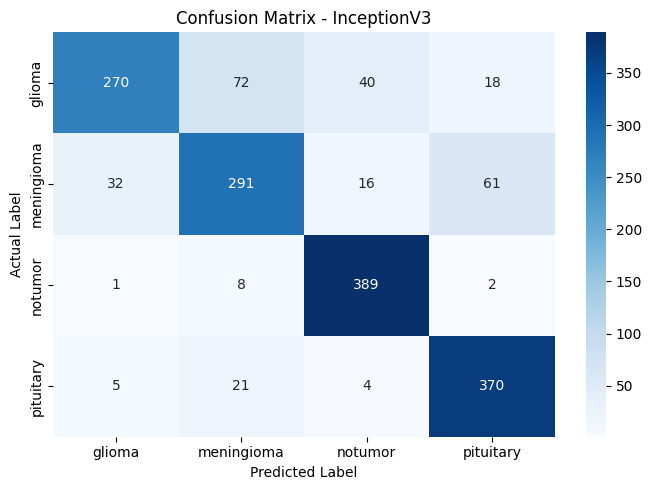

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,VGG19,0.875,0.882117,0.875,0.870837,0.971179
1,InceptionV3,0.825,0.826435,0.825,0.820874,0.953841


In [15]:
# CELL 13: Evaluate each model with report and confusion matrix

def evaluate_model(model, model_name):
    probabilities = model.predict(test_ds, verbose=1)
    y_pred = np.argmax(probabilities, axis=1)

    print("\\n", "=" * 15, model_name, "=" * 15)
    print(classification_report(
        y_true,
        y_pred,
        labels=list(range(NUM_CLASSES)),
        target_names=class_names,
        zero_division=0
    ))

    cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
    plt.figure(figsize=(7, 5))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=class_names, yticklabels=class_names
    )
    plt.title("Confusion Matrix - " + model_name)
    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")
    plt.tight_layout()
    plt.show()

    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average="weighted", zero_division=0)
    recall = recall_score(y_true, y_pred, average="weighted", zero_division=0)
    f1 = f1_score(y_true, y_pred, average="weighted", zero_division=0)

    try:
        auc = roc_auc_score(
            y_true, probabilities,
            labels=list(range(NUM_CLASSES)),
            multi_class="ovr",
            average="weighted"
        )
    except ValueError:
        auc = np.nan

    return {
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "ROC-AUC": auc
    }

results = []
results.append(evaluate_model(model_vgg19, "VGG19"))
results.append(evaluate_model(model_inception, "InceptionV3"))

results_df = pd.DataFrame(results)
display(results_df)

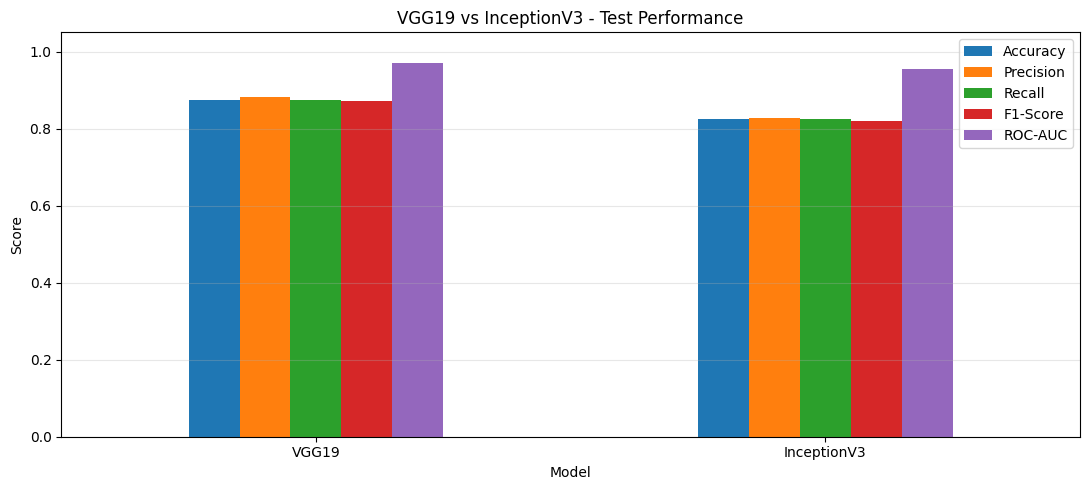

Best model based on weighted F1-score: VGG19
Measured test accuracy: 87.5 %


In [16]:
# CELL 14: Compare the two models

metric_columns = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]

ax = results_df.set_index("Model")[metric_columns].plot(
    kind="bar", figsize=(11, 5), ylim=(0, 1.05)
)
ax.set_title("VGG19 vs InceptionV3 - Test Performance")
ax.set_xlabel("Model")
ax.set_ylabel("Score")
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

best_model = results_df.sort_values("F1-Score", ascending=False).iloc[0]
print("Best model based on weighted F1-score:", best_model["Model"])
print("Measured test accuracy:", round(best_model["Accuracy"] * 100, 2), "%")